# Wine Quality Analysis & Prediction

**Name:** Surendar

## Objective
The aim of this project is to explore the Wine Quality dataset, understand which chemical properties are related to wine quality, and build a machine-learning model to predict the quality score.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [14]:
# Read the dataset
file_name = "Wine Quality Dataset.csv"
wine = pd.read_csv(file_name)

print("Dataset imported successfully.")
print("Rows:", wine.shape[0])
print("Columns:", wine.shape[1])

wine.head()

Dataset imported successfully.
Rows: 4898
Columns: 12


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [15]:
# Understand the structure of the dataset

wine.info()

print("\nColumn names:")
for col in wine.columns:
    print("-", col)

print("\nDescriptive statistics:")
wine.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB

Column names:
- fixed acidity
- volatile acidity
- citric acid
- residual sugar
- chlorides
- free sulfur dioxide
- total sulfur dioxide

,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.854788,0.843868,3.80000,6.300000,6.80000,7.3000,14.20000
volatile acidity,4898.0,0.278241,0.100795,0.08000,0.210000,0.26000,0.3200,1.10000
citric acid,4898.0,0.334192,0.121020,0.00000,0.270000,0.32000,0.3900,1.66000
residual sugar,4898.0,6.391415,5.072058,0.60000,1.700000,5.20000,9.9000,65.80000
chlorides,4898.0,0.045772,0.021848,0.00900,0.036000,0.04300,0.0500,0.34600
free sulfur dioxide,4898.0,35.308085,17.007137,2.00000,23.000000,34.00000,46.0000,289.00000
total sulfur dioxide,4898.0,138.360657,42.498065,9.00000,108.000000,134.00000,167.0000,440.00000
density,4898.0,0.994027,0.002991,0.98711,0.991723,0.99374,0.9961,1.03898
pH,4898.0,3.188267,0.151001,2.72000,3.090000,3.18000,3.2800,3.82000
sulphates,4898.0,0.489847,0.114126,0.22000,0.410000,0.47000,0.5500,1.08000


## 2. Understanding the Data

The dataset contains information about the chemical properties of wine along with its quality score. The `quality` column is the target variable that we will use for analysis and prediction.

The dataset structure, column names, data types, and descriptive statistics were examined to understand the characteristics of the data before performing further analysis.

In [16]:
# Check for missing values and duplicate rows

missing = wine.isna().sum()

print("Missing values by column:")
print(missing)

print("\nTotal missing values:", missing.sum())
print("Duplicate rows:", wine.duplicated().sum())

Missing values by column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total missing values: 0
Duplicate rows: 937


Number of wines at each quality level:
quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64


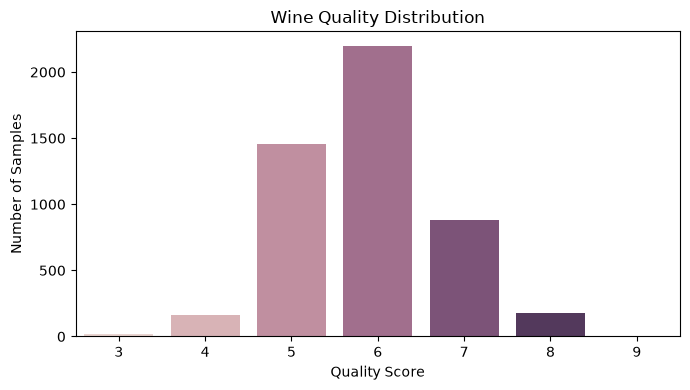

In [17]:
# Explore the distribution of wine quality scores

quality_counts = wine["quality"].value_counts().sort_index()

print("Number of wines at each quality level:")
print(quality_counts)

plt.figure(figsize=(7, 4))
sns.countplot(data=wine, x="quality", hue="quality", legend=False)
plt.title("Wine Quality Distribution")
plt.xlabel("Quality Score")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

## 4. Exploring Wine Quality

The quality scores are not evenly distributed across the dataset. Most observations are concentrated around the middle quality scores, while the lower and higher quality scores have fewer observations.

This distribution is important when building a classification model because the model has fewer examples to learn from for the less common quality classes.

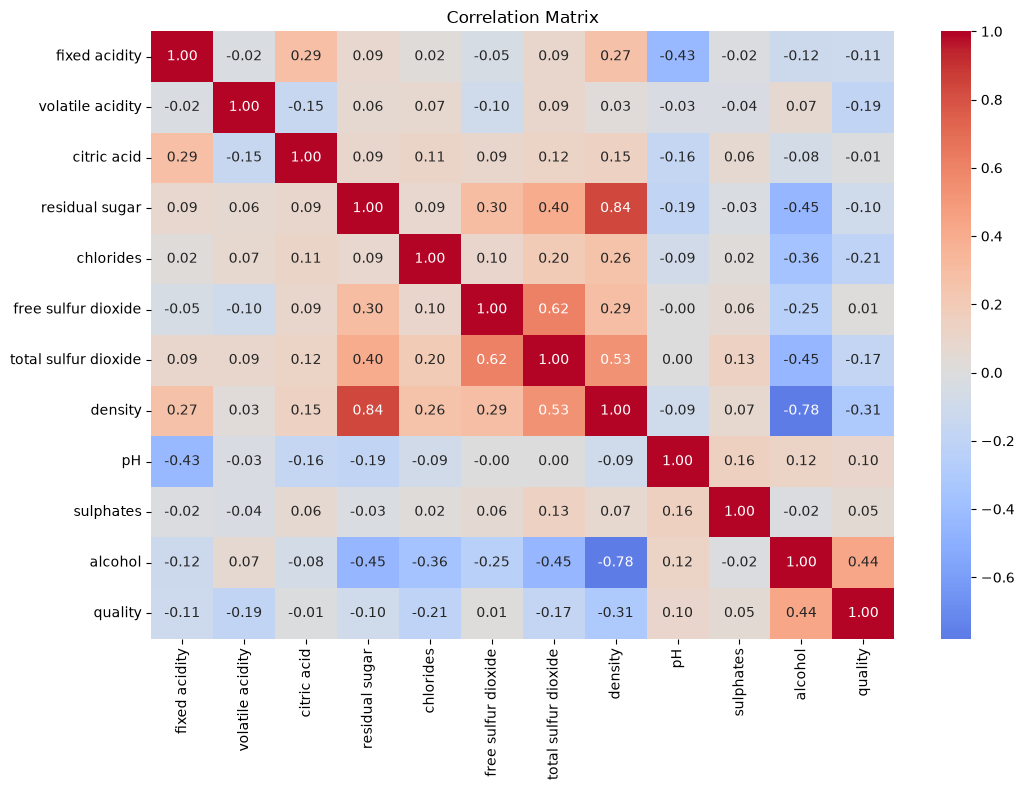

Correlation with quality:
quality                 1.000000
alcohol                 0.435575
pH                      0.099427
sulphates               0.053678
free sulfur dioxide     0.008158
citric acid            -0.009209
residual sugar         -0.097577
fixed acidity          -0.113663
total sulfur dioxide   -0.174737
volatile acidity       -0.194723
chlorides              -0.209934
density                -0.307123
Name: quality, dtype: float64


In [18]:
# Examine relationships between the numerical variables

correlations = wine.corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

print("Correlation with quality:")
print(correlations["quality"].sort_values(ascending=False))

In [19]:
# Separate the input features and target variable

X = wine.drop(columns="quality")
y = wine["quality"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=7,
    stratify=y
)

# Standardize the numerical features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Number of input features:", X_train.shape[1])

Training rows: 3918
Testing rows: 980
Number of input features: 11


## 6. Preparing Data for Machine Learning

The `quality` column is used as the target variable, while the remaining chemical properties are used as input features.

The dataset is divided into training and testing sets using an 80:20 split. Stratification is used to maintain similar proportions of the different quality classes in both sets.

The numerical features are standardized using the training data. The same transformation is then applied to the test data.

In [20]:
# Build and train the Random Forest classifier

model = RandomForestClassifier(
    n_estimators=250,
    max_depth=None,
    min_samples_leaf=2,
    random_state=7,
    n_jobs=-1
)

model.fit(X_train_scaled, y_train)

predictions = model.predict(X_test_scaled)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


## 7. Building the Prediction Model

A Random Forest classifier is used to predict the wine quality score.

The model combines multiple decision trees to make predictions. The model is trained using the training dataset and then used to predict quality scores for the unseen test dataset.

In [21]:
# Evaluate model performance

accuracy = accuracy_score(y_test, predictions)

print(f"Test accuracy: {accuracy:.3f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    predictions,
    zero_division=0
))

Test accuracy: 0.701

Detailed classification report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       1.00      0.09      0.17        33
           5       0.73      0.70      0.72       291
           6       0.67      0.82      0.74       440
           7       0.71      0.60      0.65       176
           8       0.92      0.31      0.47        35
           9       0.00      0.00      0.00         1

    accuracy                           0.70       980
   macro avg       0.58      0.36      0.39       980
weighted avg       0.72      0.70      0.69       980



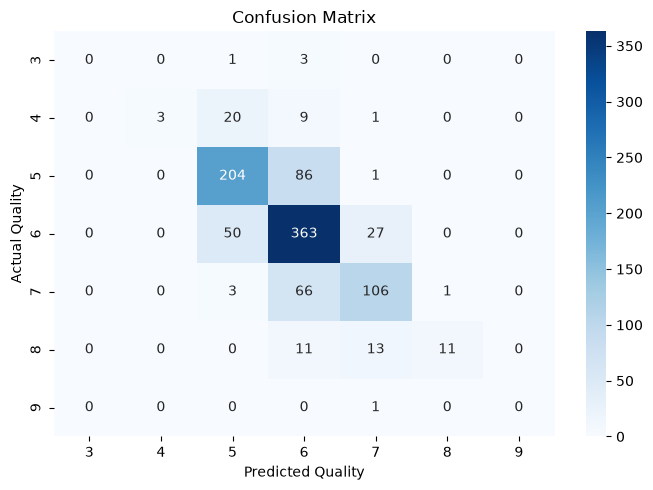

In [22]:
# Create a confusion matrix

labels = sorted(y.unique())

matrix = confusion_matrix(
    y_test,
    predictions,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels,
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")
plt.tight_layout()
plt.show()

## 8. Evaluating the Model

The model is evaluated using test accuracy and a classification report. The classification report provides precision, recall, and F1-score for each quality class.

A confusion matrix is also used to compare the actual quality scores with the predicted quality scores. This helps identify which quality classes are more frequently confused by the model.

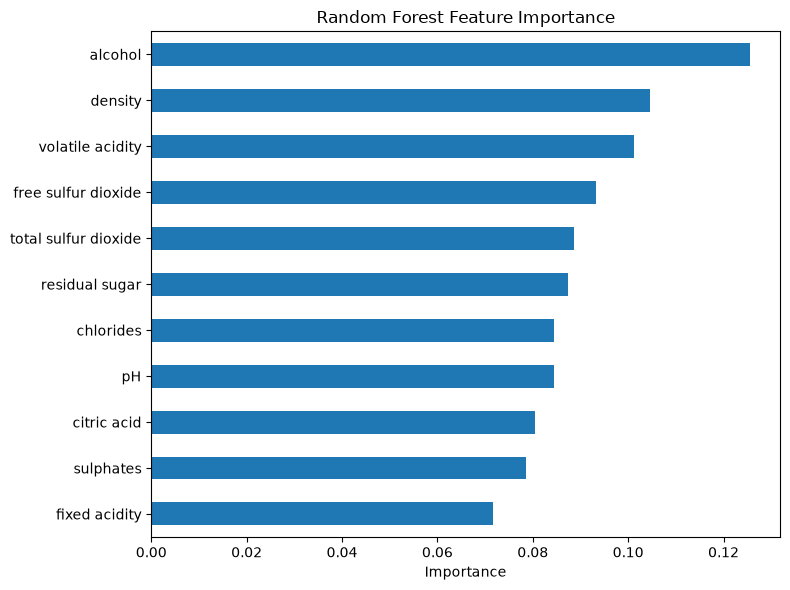

Features ranked by importance:
alcohol                 0.125559
density                 0.104604
volatile acidity        0.101268
free sulfur dioxide     0.093152
total sulfur dioxide    0.088652
residual sugar          0.087308
chlorides               0.084456
pH                      0.084353
citric acid             0.080459
sulphates               0.078480
fixed acidity           0.071711
dtype: float64


In [23]:
# Calculate Random Forest feature importance

importance = (
    pd.Series(
        model.feature_importances_,
        index=X.columns
    )
    .sort_values(ascending=True)
)

plt.figure(figsize=(8, 6))
importance.plot(kind="barh")

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print("Features ranked by importance:")
print(importance.sort_values(ascending=False))

## 9. Which Features Matter Most?

Random Forest feature importance shows how useful each input feature was when the model made its predictions.

The feature importance values describe the contribution of each variable to the model's decision-making process. They should not be interpreted as proof that a particular chemical property directly causes wine quality to increase or decrease.

In [24]:
# Summarize the main findings

quality_correlations = correlations["quality"].drop("quality")

top_feature = quality_correlations.idxmax()
lowest_feature = quality_correlations.idxmin()

missing_total = int(missing.sum())

print("Dataset size:", wine.shape)
print("Total missing values:", missing_total)
print("Most positively correlated feature:", top_feature)
print("Most negatively correlated feature:", lowest_feature)
print(f"Model accuracy on the test set: {accuracy:.3f}")

Dataset size: (4898, 12)
Total missing values: 0
Most positively correlated feature: alcohol
Most negatively correlated feature: density
Model accuracy on the test set: 0.701


## 10. Final Findings

The Wine Quality dataset was analyzed to understand the relationship between its chemical properties and wine quality scores.

The dataset contains multiple chemical measurements along with a `quality` score. The quality scores are concentrated around the middle values, while the extreme quality levels have fewer observations.

The correlation analysis was used to identify the features that have the strongest positive and negative relationships with wine quality. However, correlation does not establish a causal relationship.

A Random Forest classifier was trained using an 80:20 train-test split. The model was evaluated using test accuracy, a classification report, and a confusion matrix.

Feature importance was also examined to identify which chemical properties contributed most to the Random Forest predictions.

Overall, the analysis shows that wine quality is influenced by multiple chemical properties rather than a single measurement. The results provide a basis for further experimentation with other machine-learning models and improved handling of the less common quality classes.

### Possible Next Steps

- Compare the Random Forest model with other classification algorithms.
- Experiment with class weighting or resampling for less common quality classes.
- Treat wine quality as an ordered numerical variable and try regression models.
- Tune the Random Forest hyperparameters and compare the results.